# Tests de validation MSUC : instance IEEE 118 noeuds

Ce notebook entraine la politique SDDP sur l'instance IEEE 118 noeuds (`Data/IEEE/118_syst` : 54 groupes thermiques,
118 noeuds, 179 lignes en flux DC, d'apres `lines.csv`) puis la simule. On choisit l'horizon, le nombre de scenarios, la formulation
(3-bin ou intervalle) et les reglages de `train` (nombre d'iterations, ecart d'optimalite du MIP racine), puis on
regarde la trajectoire de la borne inferieure, le cout de la politique simulee et la repartition du temps de calcul.

C'est le notebook `validation.ipynb` restreint a l'instance IEEE : les cellules sont les memes, seules changent le
chargement de l'instance et les valeurs par defaut des parametres. Les campagnes de runs sur cette instance sont dans
`runIEEE.jl`.

Les verifications rigoureuses (borne <= optimum exact <= politique, equivalence des formulations
3-bin et intervalle, Prop. 3) sont dans `examples/toy_convergence.jl` et `examples/compare_formulations.jl` ; le
test sur l'instance IEEE (T = 4, S = 2, optimum exact par l'arbre de scenarios) est decrit dans le `README.md`.

A executer depuis la racine du depot (le kernel Julia active automatiquement ce projet).

## 1. Installation des dependances (une seule fois)

Installe les paquets listes dans `Project.toml` (JuMP, Gurobi.jl, CSV, DataFrames, NCDatasets, ...). 
Necessite une licence Gurobi valide sur la machine.

In [9]:
import Pkg
Pkg.activate(@__DIR__)  # active ce projet, quel que soit le kernel Julia choisi
Pkg.instantiate()

  Activating project at `~/Documents/MSUC`


In [10]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#43 (generic function with 1 method)

In [51]:
INSTANCE    = "118_syst"                   # dossier de Data/IEEE
T           = 24                           # horizon (nombre de pas de temps, au plus 24 : le profil de charge couvre 24 heures)
S           = 5                            # nombre de scenarios (support de l'innovation ARMA)
SIGMA       = 1.0                          # amplitude de l'alea : multiplie l'ecart-type de l'innovation ARMA (0.0 = deterministe)
ITERATIONS  = 40                           # nombre d'iterations SDDP
MIP_GAP     = 1e-2                         # ecart d'optimalite du MIP racine : 1e-2 = 1 %, 1e-3 = 0.1 %, nothing = defaut du solveur (1e-4)
PASSES_PER_MIP = 10                         # passes avant/arriere (LP) par resolution du MIP racine : 1 = usuel, 5 ou 10 = plus de coupes entre deux MIP ; ITERATIONS compte alors des cycles
N_SIMULATION = 1000                        # trajectoires tirees pour simuler la politique (toutes enumerees si S^T <= 4096)
PRINT_LEVEL = 1                            # 0 = silencieux, 1 = log complet de MSUC.train

# :threebin  -> formulation 3-bin  (Sect. 2 de l'article, coupes (12))
# :extended  -> formulation intervalle (Sect. 3 de l'article, coupes (41))
METHOD = :extended

:extended

In [52]:
FORMULATIONS = Dict(
    :threebin => (MSUC.subproblem_builder_UC_def,     MSUC.SDDPFormulation,     "3-bin"),
    :extended => (MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation, "intervalle"),
)
builder, method, label = FORMULATIONS[METHOD]

instance = MSUC.parse_IEEE(INSTANCE, optimizer, T; S = S, sigma = SIGMA)
@printf("instance IEEE %s : %d unites, %d intervalles, %d noeuds, %d lignes, T = %d, S = %d, methode = %s\n",
        INSTANCE, instance.N, sum(length(u.intervals) for u in instance.Thermalunits),
        length(instance.Demandbus), length(instance.Lines) ÷ 2, T, S, label)

instance IEEE 118_syst : 54 unites, 12495 intervalles, 118 noeuds, 179 lignes, T = 24, S = 5, methode = intervalle


In [53]:
model = MSUC.PolicyGraph(
    builder, instance, 1.0, MSUC.Graph(T + 1), method;   # force = 1 : l'amplitude de l'alea est donnee par SIGMA
    lower_bound = 0.0, optimizer = optimizer,
)

# Garde, sans toucher a l'algorithme, le planning x^k et les etats echantillonnes de chaque iteration
# (memes enregistrements que `train_job`, utilise par runIEEE.jl)
record, record_pass, _, schedules, states = MSUC.make_recorder(model)

Random.seed!(MSUC.SEED)   # meme graine que `train_job` (runIEEE.jl) : les runs sont reproductibles
MSUC.train(model; iteration_limit = ITERATIONS, mip_gap = MIP_GAP,
            passes_per_mip = PASSES_PER_MIP, print_level = PRINT_LEVEL,
            forward_pass_callback = record_pass, post_iteration_callback = record, linearization = :price)

-------------------------------------------------------------------
         MSUC.jl (c) Oscar Dowson and contributors, 2017-25
-------------------------------------------------------------------
problem
  nodes           : 25
  state variables : 56
  scenarios       : 5.96046e+16
  existing cuts   : false
subproblem structure
  VariableRef                             : [1096, 16550]
  AffExpr in MOI.EqualTo{Float64}         : [478, 5311]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 413]
  AffExpr in MOI.LessThan{Float64}        : [574, 5184]
  VariableRef in MOI.EqualTo{Float64}     : [271, 271]
  VariableRef in MOI.GreaterThan{Float64} : [290, 12549]
  VariableRef in MOI.LessThan{Float64}    : [54, 54]
  VariableRef in MOI.ZeroOne              : [3942, 3942]
numerical stability report
  matrix range     [1e-01, 4e+02]
  objective range  [1e+00, 7e+02]
  bounds range     [2e+01, 4e+02]
  rhs range        [1e+00, 5e+02]
---------------------------------------------------------------

innovation : 5 points de -4.87 % a 4.87 % (ecart-type 1.70 %, soit sigma = 1.00) ; 5^24 trajectoires possibles, 200 tirees, 50 visitees par les passes avant


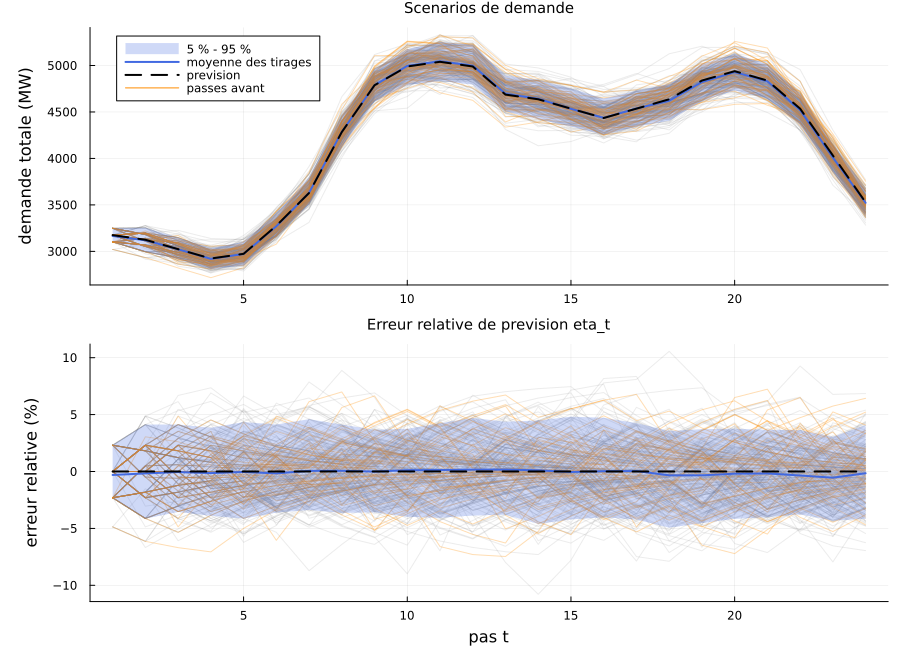

In [ ]:
# Scenarios de demande. La demande du noeud b a l'etape t vaut Demandbus[b][t] * (1 + eta_t), ou
# eta_t = S_eta zeta_t est l'erreur relative de prevision (la meme sur tous les noeuds), zeta_t = Psi zeta_{t-1} + E xi_t,
# et l'innovation xi_t prend S valeurs : il y a S^T trajectoires possibles, dont on tire ici N_SCENARIOS au hasard.
using Plots, Statistics, Random, Printf

N_SCENARIOS = 200            # trajectoires tirees dans la loi du modele
AVEC_PASSES_AVANT = true     # superposer les trajectoires visitees par les passes avant de l'entrainement

arma = instance.arma
prevision = [sum(instance.Demandbus[b][t] for b in eachindex(instance.Demandbus)) for t in 1:T]   # demande totale prevue

# erreur relative eta_1, ..., eta_T d'une suite d'innovations xi_1, ..., xi_T
function erreur_relative(innovations)
    zeta = copy(arma.zeta0)
    eta = zeros(length(innovations))
    for (t, xi) in enumerate(innovations)
        zeta = arma.Psi * zeta + arma.E * xi
        eta[t] = sum(arma.S_eta[1, :] .* zeta)
    end
    return eta
end

let
    rng = MersenneTwister(MSUC.SEED)
    cumul = cumsum(arma.probability)
    tirer() = arma.support[min(searchsortedfirst(cumul, rand(rng)), length(cumul))]
    eta = reduce(hcat, [erreur_relative([tirer() for _ in 1:T]) for _ in 1:N_SCENARIOS])      # T x N_SCENARIOS

    # trajectoires visitees par les passes avant : zeta_t est l'etat a la sortie du noeud t + 1
    visite = Matrix{Float64}(undef, T, 0)
    if AVEC_PASSES_AVANT && isdefined(Main, :states)
        trajectoires = [vec(arma.S_eta[1:1, :] * reduce(hcat, p.sampled_states_zeta)[:, 2:end]) for k in eachindex(states) for p in states[k]]
        visite = reduce(hcat, trajectoires)
    end

    # Les scenarios viennent de l'instance telle qu'elle a ete construite (cellule de l'instance) : si SIGMA ou S ont
    # change depuis, il faut relancer cette cellule (puis l'entrainement) pour que le trace les prenne en compte.
    xs = [x[1] for x in arma.support]
    S_instance = length(xs)
    ecart_type = sqrt(sum(arma.probability .* xs .^ 2))
    sigma_instance = ecart_type / sqrt(MSUC.ARMA_INNOVATION_VARIANCE)
    @printf("innovation : %d points de %.2f %% a %.2f %% (ecart-type %.2f %%, soit sigma = %.2f) ; %d^%d trajectoires possibles, %d tirees",
            S_instance, 100 * minimum(xs), 100 * maximum(xs), 100 * ecart_type, sigma_instance, S_instance, T, N_SCENARIOS)
    size(visite, 2) > 0 && @printf(", %d visitees par les passes avant", size(visite, 2))
    println()
    S_instance == 1 && println("S = 1 : l'innovation est nulle (un seul point, 0), sigma n'a aucun effet")
    if S_instance != S || (S_instance > 1 && !isapprox(sigma_instance, SIGMA; atol = 1e-6))
        @warn "l'instance a ete construite avec S = $S_instance et sigma = $(round(sigma_instance; digits = 3)), alors que S = $S et SIGMA = $SIGMA : relancer la cellule de l'instance (et celle de l'entrainement)"
    end

    function panneau(valeurs, nominal, visitees; ylabel, titre)
        bas = [quantile(view(valeurs, t, :), 0.05) for t in 1:T]
        haut = [quantile(view(valeurs, t, :), 0.95) for t in 1:T]
        p = plot(1:T, valeurs; color = :gray, alpha = 0.15, label = "", ylabel = ylabel, title = titre, titlefontsize = 10)
        size(visitees, 2) > 0 && plot!(p, 1:T, visitees; color = :darkorange, alpha = 0.3, label = "")
        plot!(p, 1:T, bas; fillrange = haut, fillalpha = 0.25, color = :royalblue, linewidth = 0, label = "5 % - 95 %")
        plot!(p, 1:T, vec(mean(valeurs; dims = 2)); color = :royalblue, linewidth = 2, label = "moyenne des tirages")
        plot!(p, 1:T, nominal; color = :black, linewidth = 2, linestyle = :dash, label = "prevision")
        size(visitees, 2) > 0 && plot!(p, [NaN], [NaN]; color = :darkorange, label = "passes avant")
        return p
    end
    p1 = panneau(prevision .* (1 .+ eta), prevision, prevision .* (1 .+ visite); ylabel = "demande totale (MW)", titre = "Scenarios de demande")
    p2 = panneau(100 .* eta, zeros(T), 100 .* visite; ylabel = "erreur relative (%)", titre = "Erreur relative de prevision eta_t")
    plot(p1, p2; layout = (2, 1), size = (900, 650), xlabel = ["" "pas t"], legend = [:topleft :none], left_margin = 6Plots.mm)
end

### Resultats : trajectoire de la borne et cout de la politique simulee

it   1   borne = 1712.48   incumbent = 0.00
it   2   borne = 8691.55   incumbent = 0.92
it   3   borne = 9576.95   incumbent = 0.81
it   4   borne = 9693.44   incumbent = 0.71
it   5   borne = 9752.61   incumbent = 0.68
it   6   borne = 9904.52   incumbent = 0.37
it   7   borne = 11521.37   incumbent = 0.49
it   8   borne = 11567.29   incumbent = 0.95
it   9   borne = 899426.79   incumbent = 0.00
it  10   borne = 899885.51   incumbent = 0.01
it  11   borne = 901206.09   incumbent = 0.03
it  12   borne = 901811.78   incumbent = 0.03
it  13   borne = 1177218.49   incumbent = 0.90
it  14   borne = 1177936.50   incumbent = 0.96
it  15   borne = 1178048.32   incumbent = 0.05
it  16   borne = 1178101.49   incumbent = 0.05
it  17   borne = 1180136.20   incumbent = 0.50
it  18   borne = 1180422.52   incumbent = 0.03
it  19   borne = 1180496.30   incumbent = 0.85
it  20   borne = 1181525.03   incumbent = 0.10
it  21   borne = 1181976.47   incumbent = 0.02
it  22   borne = 1182962.94   incumbent

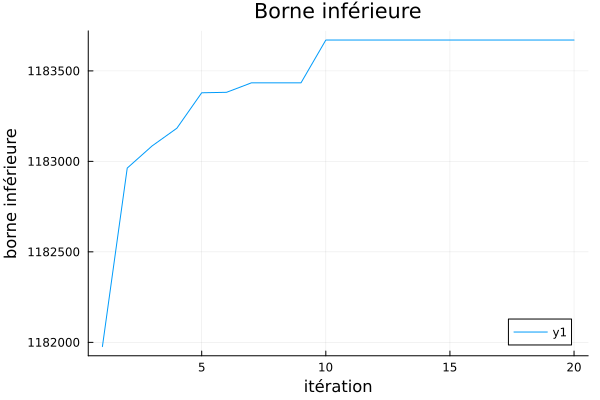

In [63]:
using Plots
log = model.most_recent_training_results.log
for l in log
    @printf("it %3d   borne = %.2f   incumbent = %.2f\n", l.iteration, l.bound, 100*(l.incumbent-l.bound)/l.incumbent)
end
plot([l.bound for l in log if l.iteration >= max(10, ITERATIONS ÷ 2 + 1)], title = "Borne inférieure", xlabel = "itération", ylabel = "borne inférieure")

In [55]:
t_sim = @elapsed sim = MSUC.simulate(model; samples = N_SIMULATION, seed = MSUC.SEED)   # meme graine que `simulate_job` (runIEEE.jl)
@printf("\ncout de la politique simulee = %.2f  (%d chemins, exhaustif = %s, %.1f s)\n",
        sim.cost, sim.npaths, sim.exhaustive, t_sim)
@printf("intervalle de confiance a 95 %% : [%.2f, %.2f]  (erreur standard %.2f)\n",
        sim.ci95[1], sim.ci95[2], sim.stderr)
@printf("borne finale = %.2f  ->  encadrement relatif = %.2e\n",
        log[end].bound, 100*(sim.cost - log[end].bound) / abs(log[end].bound))


cout de la politique simulee = 1195512.36  (1000 chemins, exhaustif = false, 29.3 s)
intervalle de confiance a 95 % : [1193435.14, 1197589.58]  (erreur standard 1059.81)
borne finale = 1183670.32  ->  encadrement relatif = 1.00e+00


### Diagnostic : intervalles choisis et etats echantillonnes

`schedules[k]` est le planning x^k choisi par le MIP racine a l'iteration k (en formulation intervalle,
ses intervalles sont dans `selected`) et `states[k][p]` la trajectoire de la passe avant p de l'iteration k :
`sampled_states_power[n]` et `sampled_states_zeta[n]` sont l'etat (production y, etat d'incertitude zeta) a la
sortie du noeud n ; le noeud 1 est l'etat initial et le noeud n l'etat a la fin du pas n-1.

La premiere cellule resume toutes les iterations (borne, incumbent, planning nouveau ou deja vu, variation des
etats echantillonnes) ; la seconde detaille une iteration en la comparant a la precedente ; la troisieme compare
y^k a y(gamma^k, ytilde^{k-1}) = somme, sur les intervalles choisis a l'iteration k, des points de linearisation
ytilde^{k-1}_{a,b,t} des coupes de l'iteration k-1 (la production visitee a l'iteration k-1 si l'intervalle y etait
deja choisi ou atteignable depuis un intervalle choisi, la production maximale atteignable ybar sinon) : c'est la production que ces coupes « attendent » pour le planning gamma^k. Un
ecart signifie que la coupe est evaluee en un autre point que celui ou elle a ete linearisee.

In [56]:
# Intervalles (unite, a, b) du planning x^k : l'unite est allumee aux pas a, ..., b-1 (b = T+1 : jusqu'a la fin
# de l'horizon ; a <= 0 : intervalle initial, l'unite est deja allumee au depart).
function intervalles(k)
    s, I = schedules[k], instance.intervals
    isempty(s.selected) || return [(I.unit[id], I.a[id], I.b[id]) for id in s.selected]
    # 3-bin : aucun intervalle n'est choisi, on relit les periodes de marche de u (colonne t+1 = pas t)
    out = Tuple{Int,Int,Int}[]
    for i in 1:instance.N
        t = 0
        while t <= T
            if s.u[i, t+1] > 0.5
                a = t
                while t < T && s.u[i, t+2] > 0.5
                    t += 1
                end
                push!(out, (i, a, t + 1))
            end
            t += 1
        end
    end
    return out
end

# Intervalles de l'iteration k, unite par unite
function par_unite(k)
    d = [Tuple{Int,Int}[] for _ in 1:instance.N]
    for (i, a, b) in intervalles(k)
        push!(d[i], (a, b))
    end
    return sort!.(d)
end

# Production y (unites x noeuds) le long de la passe avant p de l'iteration k
production(k, p = 1) = reduce(hcat, states[k][p].sampled_states_power)

# y(gamma^k, ytilde^{k-1}) = somme des gamma^k_{a,b} ytilde^{k-1}_{a,b,t} : la production que les coupes de
# l'iteration k-1 « attendent » quand le planning est gamma^k. ytilde^{k-1}_{a,b,t} est le point ou la coupe de
# l'iteration k-1 a ete linearisee pour l'intervalle [a, b] : la production visitee y^{k-1}_t si l'intervalle
# etait deja choisi a l'iteration k-1 ou atteignable depuis un intervalle choisi, la production maximale atteignable ybar sinon. Seuls les intervalles actifs au pas t+1 portent un
# terme en y_t dans la coupe ; ailleurs la coupe ne depend pas de y_t et `attendu` vaut NaN. Colonne n = noeud n
# = pas n-1. `nouveau[i, n]` : l'intervalle n'etait pas choisi a l'iteration k-1.
function y_gamma(k)
    I = instance.intervals
    visite = production(k - 1, length(states[k-1]))    # derniere passe de l'iteration k-1 : la coupe la plus recente
    deja = Set(schedules[k-1].selected)
    choisis = [Tuple{Int,Int}[] for _ in 1:instance.N]    # intervalles choisis de chaque unite a l'iteration k-1
    for id in schedules[k-1].selected
        push!(choisis[I.unit[id]], (I.a[id], I.b[id]))
    end
    attendu = fill(NaN, instance.N, T + 1)
    nouveau = falses(instance.N, T + 1)
    for id in schedules[k].selected
        i, a, b = I.unit[id], I.a[id], I.b[id]
        for t in 0:(T-1)
            MSUC.is_on_interval(a, b, t + 1) || continue
            y = visite[i, t+1]
            attendu[i, t+1] = MSUC.linearization_point(instance.Thermalunits[i], a, b, t, T, y, id in deja, choisis[i])
            nouveau[i, t+1] = !(id in deja)
        end
    end
    return attendu, nouveau
end

# Plus grand ecart en valeur absolue, sans compter les NaN
max_abs(M) = maximum(abs, filter(!isnan, M); init = 0.0)

K = length(log)
@printf("%4s %12s %12s %10s %6s %9s %10s %10s  %s\n",
        "it", "borne", "incumbent", "ecart rel.", "#int.", "#changees", "max|dy|", "max|y-yg|", "planning")
for k in 1:K
    changees = k == 1 ? "-" : string(count(par_unite(k) .!= par_unite(k - 1)))   # unites dont les intervalles different de k-1
    dy = k == 1 ? "-" : @sprintf("%.3g", maximum(abs, production(k) .- production(k - 1)))
    dyg = METHOD == :extended && k >= 2 ? @sprintf("%.3g", max_abs(production(k) .- y_gamma(k)[1])) : "-"   # y^k - y(gamma^k, ytilde^{k-1})
    vu = findfirst(j -> schedules[j].x == schedules[k].x, 1:k-1)
    @printf("%4d %12.2f %12.2f %10.2e %6d %9s %10s %10s  %s\n",
            k, log[k].bound, log[k].incumbent, (log[k].incumbent - log[k].bound) / abs(log[k].incumbent),
            length(intervalles(k)), changees, dy, dyg, vu === nothing ? "nouveau" : "identique a l'iteration $vu")
end

  it        borne    incumbent ecart rel.  #int. #changees    max|dy|  max|y-yg|  planning
   1      1712.48      1712.48   0.00e+00      6         -          -          -  nouveau
   2      8691.55      8772.21   9.20e-03     17        16        420        220  nouveau
   3      9576.95      9655.57   8.14e-03     29        21        420        200  nouveau
   4      9693.44      9763.02   7.13e-03     24        12        420        150  nouveau
   5      9752.61      9819.30   6.79e-03     27        16        420        200  nouveau
   6      9904.52      9941.40   3.71e-03     24        10        420        220  nouveau
   7     11521.37     11577.62   4.86e-03     30        18        420        220  nouveau
   8     11567.29     11677.77   9.46e-03     29         7        420        200  nouveau
   9    899426.79    899426.79   0.00e+00     55        48        420        219  nouveau
  10    899885.51    899967.90   9.16e-05     57         4        300        200  nouveau
  11    9

Intervalles de l'iteration 40 ; * : unites qui different de l'iteration 39

   unite   1 : [1, 2]
   unite   2 : [1, 2]
   unite   3 : [1, 2]
   unite   4 : [1, 25]
   unite   5 : [1, 25]
   unite   6 : [1, 2]
   unite   7 : [9, 14]
   unite   8 : [1, 2]
   unite   9 : [1, 2]
   unite  10 : [1, 25]
   unite  11 : [-7, 25]
   unite  12 : [1, 2]
   unite  13 : [1, 2]
   unite  14 : [9, 14]
   unite  15 : [1, 2]
   unite  16 : [9, 14]
   unite  17 : [1, 2]
   unite  18 : [1, 2]
   unite  20 : [-7, 25]
   unite  21 : [-7, 25]
   unite  23 : [1, 6]
   unite  24 : [1, 24]
   unite  25 : [1, 24]
   unite  27 : [-9, 25]
   unite  28 : [-9, 25]
   unite  29 : [1, 25]
   unite  30 : [1, 5]
   unite  31 : [1, 2]
   unite  32 : [1, 2]
   unite  36 : [1, 25]
   unite  38 : [1, 2]
   unite  39 : [-7, 25]
   unite  40 : [1, 25]
   unite  41 : [1, 2]
   unite  42 : [1, 2]
   unite  43 : [1, 25]
   unite  44 : [1, 25]
   unite  45 : [1, 24]
   unite  46 : [1, 2]
   unite  47 : [1, 6]
   unite  48 : [1,

2×25 Matrix{Float64}:
 0.0  0.0  0.0  -0.0231  -0.0182  …  -0.0257  -0.0199  -0.0134  0.0141
 0.0  0.0  0.0  -0.0231   0.0        -0.0231   0.0      0.0     0.0231


Unites dont la production y differe d'au moins 1e-6 de celle de l'iteration 39 :
   unite   4 : ecart max  150.000 au noeud 23  (y = 150.000 contre 300.000)
   unite   5 : ecart max  150.000 au noeud 25  (y = 150.000 contre 300.000)
   unite   7 : ecart max   42.016 au noeud 12  (y = 67.016 contre 25.000)
   unite  10 : ecart max  150.000 au noeud 17  (y = 150.000 contre 300.000)
   unite  14 : ecart max   28.472 au noeud 12  (y = 53.472 contre 25.000)
   unite  16 : ecart max   19.285 au noeud 12  (y = 44.285 contre 25.000)
   unite  20 : ecart max   87.935 au noeud  4  (y = 53.981 contre 141.916)
   unite  21 : ecart max  109.735 au noeud  5  (y = 125.000 contre 234.735)
   unite  24 : ecart max  147.819 au noeud 22  (y = 52.181 contre 200.000)
   unite  25 : ecart max  150.000 au noeud 13  (y = 200.000 contre 50.000)
   unite  29 : ecart max  150.000 au noeud 25  (y = 300.000 contre 150.000)
   unite  36 : ecart max  150.000 au noeud  8  (y = 150.000 contre 300.000)
   unite  40 : 

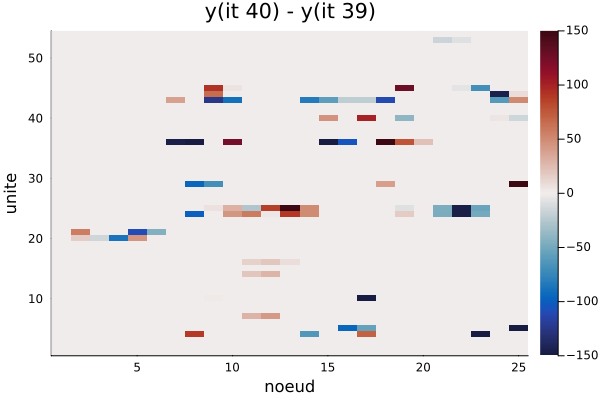

In [48]:
ITERATION = K    # iteration a examiner, comparee a la precedente
PASSE = 4        # passe avant de cette iteration (PASSES_PER_MIP passes par iteration)

actuel, avant = par_unite(ITERATION), par_unite(max(ITERATION - 1, 1))
texte(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

println("Intervalles de l'iteration $ITERATION ; * : unites qui different de l'iteration $(ITERATION - 1)\n")
for i in 1:instance.N
    isempty(actuel[i]) && isempty(avant[i]) && continue
    if actuel[i] == avant[i]
        println("   unite ", lpad(i, 3), " : ", texte(actuel[i]))
    else
        println(" * unite ", lpad(i, 3), " : ", texte(avant[i]), "  ->  ", texte(actuel[i]))
    end
end

y, y_avant = production(ITERATION, PASSE), production(max(ITERATION - 1, 1), PASSE)
zeta = reduce(hcat, states[ITERATION][PASSE].sampled_states_zeta)    # composantes de zeta x noeuds
dy = y .- y_avant

println("\nEtats echantillonnes de l'iteration $ITERATION (passe $PASSE) ; zeta (composantes x noeuds) :")
display(round.(zeta; digits = 4))
println("\nUnites dont la production y differe d'au moins 1e-6 de celle de l'iteration $(ITERATION - 1) :")
for i in findall(i -> maximum(abs, dy[i, :]) > 1e-6, 1:instance.N)
    n = argmax(abs.(dy[i, :]))
    @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f)\n", i, abs(dy[i, n]), n, y[i, n], y_avant[i, n])
end

m = max(maximum(abs, dy), 1e-9)
heatmap(dy; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
        title = "y(it $ITERATION) - y(it $(ITERATION - 1))")

Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration 40, passe 4)
(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration 39) :

   unite   4 : ecart max  150.000 au noeud 23  (y = 150.000 contre 300.000 ; intervalle deja choisi)
   unite   5 : ecart max   96.748 au noeud 16  (y = 203.252 contre 300.000 ; intervalle deja choisi)
   unite   7 : ecart max   42.016 au noeud 12  (y = 67.016 contre 25.000 ; intervalle deja choisi)
   unite  10 : ecart max  150.000 au noeud 17  (y = 150.000 contre 300.000 ; intervalle deja choisi)
   unite  14 : ecart max   28.472 au noeud 12  (y = 53.472 contre 25.000 ; intervalle deja choisi)
   unite  16 : ecart max   19.285 au noeud 12  (y = 44.285 contre 25.000 ; intervalle deja choisi)
   unite  20 : ecart max   87.935 au noeud  4  (y = 53.981 contre 141.916 ; intervalle deja choisi)
   unite  21 : ecart max  109.735 au noeud  5  (y = 125.000 contre 234.735 ; intervalle deja choisi)
   unite  24 : ecart max  147.81

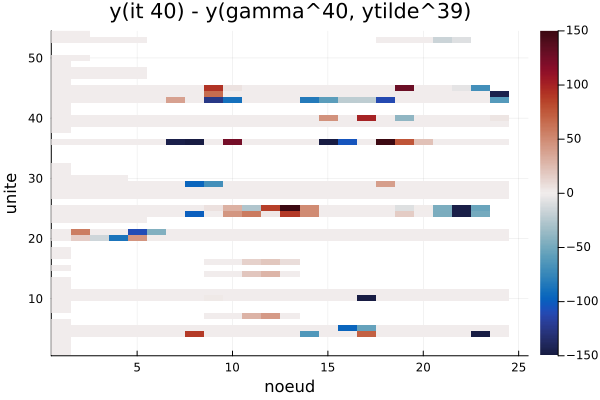

In [49]:
# y^k contre y(gamma^k, ytilde^{k-1}) a l'iteration ITERATION (definie dans la cellule precedente)
if METHOD != :extended || ITERATION < 2
    println("comparaison disponible en formulation intervalle, a partir de l'iteration 2")
else
    reel = production(ITERATION, PASSE)
    attendu, nouveau = y_gamma(ITERATION)
    ecart = reel .- attendu

    println("Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration $ITERATION, passe $PASSE)")
    println("(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration $(ITERATION - 1)) :\n")
    for i in 1:instance.N
        valides = findall(!isnan, ecart[i, :])
        isempty(valides) && continue
        n = valides[argmax(abs.(ecart[i, valides]))]
        abs(ecart[i, n]) > 1e-6 || continue
        @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f ; intervalle %s)\n",
                i, abs(ecart[i, n]), n, reel[i, n], attendu[i, n], nouveau[i, n] ? "nouveau" : "deja choisi")
    end
    @printf("\n%d couples (unite, noeud) compares, dont %d avec un intervalle nouveau ; ecart max = %.3f\n",
            count(!isnan, ecart), count(nouveau), max_abs(ecart))

    m = max(max_abs(ecart), 1e-9)
    heatmap(ecart; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "y(it $ITERATION) - y(gamma^$ITERATION, ytilde^$(ITERATION - 1))")
end

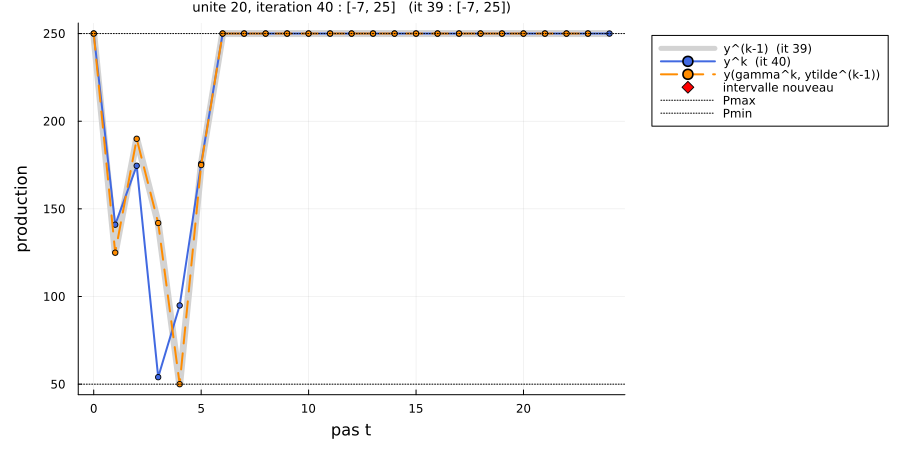

In [50]:
UNITE =  20   # unite a tracer ; l'iteration et la passe sont ITERATION et PASSE de la cellule de detail

# Trajectoires de la production de l'unite : y^k (iteration k), y^{k-1} (iteration k-1, derniere passe : celle dont
# les coupes sont les plus recentes) et y(gamma^k, ytilde^{k-1}). Losanges rouges : l'intervalle n'etait pas choisi
# a l'iteration k-1, ytilde vaut y (atteignable depuis un intervalle choisi) ou ybar ; les trous de la courbe orange sont les pas ou la coupe ne
# depend pas de y_t. Le pas t est celui du noeud n = t+1.
let
    unit, k = instance.Thermalunits[UNITE], ITERATION
    avant = max(k - 1, 1)
    y_k = production(k, PASSE)[UNITE, :]
    y_avant = production(avant, length(states[avant]))[UNITE, :]
    attendu, nouveau = METHOD == :extended && k >= 2 ? y_gamma(k) : (fill(NaN, instance.N, T + 1), falses(instance.N, T + 1))
    decrit(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

    p = plot(0:T, y_avant; label = "y^(k-1)  (it $avant)", color = :lightgray, linewidth = 7,
             xlabel = "pas t", ylabel = "production", legend = :outertopright, titlefontsize = 9, size = (900, 450),
             left_margin = 6Plots.mm, bottom_margin = 5Plots.mm,
             title = "unite $UNITE, iteration $k : $(decrit(par_unite(k)[UNITE]))   (it $avant : $(decrit(par_unite(avant)[UNITE])))")
    plot!(p, 0:T, y_k; label = "y^k  (it $k)", color = :royalblue, linewidth = 2, marker = :circle, markersize = 3)
    plot!(p, 0:T, attendu[UNITE, :]; label = "y(gamma^k, ytilde^(k-1))", color = :darkorange,
          linewidth = 2, linestyle = :dash, marker = :circle, markersize = 3)
    scatter!(p, 0:T, [nouveau[UNITE, n] ? attendu[UNITE, n] : NaN for n in 1:T+1];
             label = "intervalle nouveau", color = :red, marker = :diamond, markersize = 6)
    hline!(p, [unit.MaxPower]; label = "Pmax", color = :black, linestyle = :dot)
    hline!(p, [unit.MinPower]; label = "Pmin", color = :black, linestyle = :dot)
    p
end

In [ ]:
# Contribution de chaque unite a la variation de la valeur de la coupe de l'iteration k-1 quand l'etat visite y^k
# s'ecarte du point y(gamma^k, ytilde^{k-1}) ou elle a ete linearisee. La coupe est affine en y :
#     coupe(gamma, y) = alpha + delta.zeta + somme, sur les intervalles choisis, de (tau_id + beta_id y_unite),
# donc coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1})) = somme_j beta_j (y^k_j - ytilde_j), et chaque terme est la
# contribution de l'unite j. Positive : la coupe est plus haute (futur plus cher) au point visite qu'au point de
# linearisation ; negative : plus basse. Signe de la pente beta_j : < 0, produire plus aujourd'hui fait baisser le
# cout futur (la montee en puissance est valorisee) ; = 0, branche limitee par la capacite ; > 0, produire coute.
# Le noeud n est l'etat y_t avec t = n-1 ; seuls les noeuds 2 a T portent une coupe d'etape.
if METHOD != :extended || ITERATION < 2
    println("disponible en formulation intervalle, a partir de l'iteration 2")
else
    k, unit = ITERATION, instance.Thermalunits[UNITE]
    I = instance.intervals
    reel = production(k, PASSE)
    attendu, nouveau = y_gamma(k)
    # coupe de la derniere passe de l'iteration k-1 : position 1 = coupe triviale, puis PASSES_PER_MIP par iteration
    position = 1 + (k - 1) * PASSES_PER_MIP

    # intervalle de gamma^k actif au noeud n (pas t+1 = n) pour chaque unite
    ident = zeros(Int, instance.N, T + 1)
    for id in schedules[k].selected, n in 1:T
        MSUC.is_on_interval(I.a[id], I.b[id], n) && (ident[I.unit[id], n] = id)
    end

    pente = fill(NaN, instance.N, T + 1)     # beta_j de la coupe
    contribution = fill(NaN, instance.N, T + 1)
    erreurs = Float64[]
    for n in 2:T
        cut = model[n].cuts[position]
        for i in 1:instance.N
            ident[i, n] == 0 && continue
            pente[i, n] = cut.beta[ident[i, n]]
            contribution[i, n] = pente[i, n] * (reel[i, n] - attendu[i, n])
        end
        # verification : somme des contributions = coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1}))
        zeta = states[k][PASSE].sampled_states_zeta[n]
        valeur(y) = cut.alpha + sum(cut.delta .* zeta) +
                    sum(cut.beta[id] * y[I.unit[id]] + cut.tau[id] for id in schedules[k].selected)
        y_tilde = ifelse.(isnan.(attendu[:, n]), reel[:, n], attendu[:, n])
        push!(erreurs, abs(valeur(reel[:, n]) - valeur(y_tilde) - sum(filter(!isnan, contribution[:, n]); init = 0.0)))
    end
    @printf("iteration %d, passe %d : coupe de l'iteration %d (position %d). Ecart entre la somme des contributions et la\n", k, PASSE, k - 1, position)
    @printf("difference des valeurs de la coupe, au pire noeud : %.2e\n\n", maximum(erreurs))

    # par noeud : variation totale de la valeur de la coupe, et ses parts positive et negative
    println("noeud  variation de la coupe   dont positive   dont negative")
    for n in 2:T
        c = filter(!isnan, contribution[:, n])
        @printf("%5d %20.1f %15.1f %15.1f\n", n, sum(c; init = 0.0), sum(x -> max(x, 0.0), c; init = 0.0), sum(x -> min(x, 0.0), c; init = 0.0))
    end

    # par unite, sur tous les noeuds : les unites qui pesent le plus
    totaux = [sum(filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    absolus = [sum(abs, filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    println("\nunites qui contribuent le plus (somme sur les noeuds, et somme des valeurs absolues) :")
    for i in sortperm(absolus; rev = true)[1:min(10, instance.N)]
        @printf("   unite %3d : somme = %12.1f   somme des |.| = %12.1f\n", i, totaux[i], absolus[i])
    end

    # detail de l'unite UNITE
    println("\nunite $UNITE : Pmin = $(unit.MinPower), Pmax = $(unit.MaxPower), montee max R_up = $(unit.DeltaRampUp), descente max R_dn = $(unit.DeltaRampDown), cout lineaire = $(unit.LinearTerm)")
    println("noeud   y^k    y~^(k-1)   ecart    pente beta   contribution   montee y^k    intervalle")
    for n in 2:T
        id = ident[UNITE, n]
        id == 0 && continue
        @printf("%5d %7.1f %9.1f %8.1f %12.3f %13.1f %12.1f    [%d, %d] %s\n", n, reel[UNITE, n], attendu[UNITE, n], reel[UNITE, n] - attendu[UNITE, n],
                pente[UNITE, n], contribution[UNITE, n], reel[UNITE, n] - reel[UNITE, n-1], I.a[id], I.b[id], nouveau[UNITE, n] ? "(nouveau)" : "")
    end

    m = max(maximum(abs, filter(!isnan, contribution); init = 0.0), 1e-9)
    heatmap(contribution; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "contribution a coupe(y^k) - coupe(y(gamma^k, ytilde^(k-1))), it $k")
end

### Temps de calcul par poste

Chronometres de `train` : racine (MIP), passe avant, passe arriere (resolution des LP, calcul des
coefficients des coupes, ajout des coupes) et mise a jour du planning.

In [26]:
MSUC.TimerOutputs.print_timer(stdout, model.timer_output; compact = true)

─────────────────────────────────────────────────────────────────────
                                          Time          Allocations  
                                    ───────────────   ───────────────
          Total measured:                3057s            4.48GiB    

Section                     ncalls     time    %tot     alloc    %tot
─────────────────────────────────────────────────────────────────────
solve_first_stage_problem       50     111s   90.2%   39.9MiB    2.0%
backward_pass                   50    8.07s    6.6%   1.19GiB   61.7%
  solve_subproblem           6.00k    5.59s    4.6%    451MiB   22.8%
    get_dual_solution        6.00k    435ms    0.4%    231MiB   11.7%
  compute_coefficients       1.20k    1.38s    1.1%    540MiB   27.3%
  add_cut                    1.20k    1.10s    0.9%    228MiB   11.5%
forward_pass                    50    3.32s    2.7%    372MiB   18.8%
  solve_subproblem           1.20k    2.63s    2.1%    133MiB    6.7%
    get_dual_soluti

### Temps du MIP racine par iteration

Le probleme racine est un MIP resolu a chaque iteration : c'est en general le poste dominant de `train`.
Son temps croit avec le nombre de coupes accumulees ; l'option `MIP_GAP` (cellule des parametres) permet de l'accelerer.

MIP racine : 70.4 s au total, soit 50 % du temps d'entrainement (141.7 s)


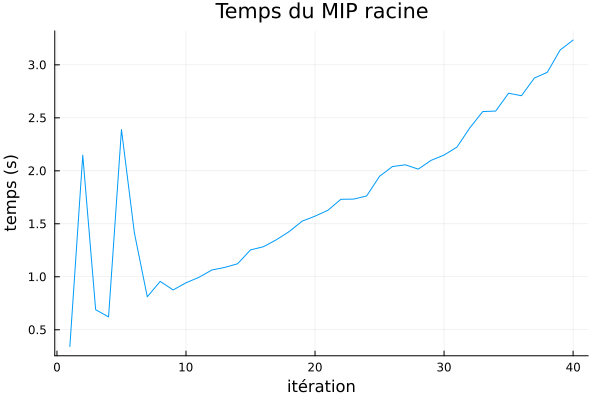

In [57]:
using Plots
t_mip = model[1].computation_time[1:length(log)]   # une resolution du MIP racine par iteration
@printf("MIP racine : %.1f s au total, soit %.0f %% du temps d'entrainement (%.1f s)\n",
        sum(t_mip), 100 * sum(t_mip) / log[end].time, log[end].time)
plot(t_mip, title = "Temps du MIP racine", xlabel = "itération", ylabel = "temps (s)", legend = false)